# PHYS20762
# Project 3: Monte-Carlo Techniques
# Neutron Transport and Scattering Through a Shielding Layer

**Arppan Enchackal**
11306450

May 2026

This project sets out to:

- Generate and validate random numbers using numpy.random.uniform() are distributed uniformly.
- Compare and identify spectral issues in different random number distributions.
- Neutron free path sampling using exponential random number generator.
- Produce isotropic unit vectors for random steps in 3 dimensions.
- Simulate neutrons in water, lead and graphite and calculate transmission, absorption and reflection ratios.
- Explore slab thickness dependence on reflection, absorption and transmission ratios.
- 

To stretch myself and as an extension:
- Implement the Woodcock method to explore neutron paths in two slabs of equal thickness but different materials.
- Pie charts and tables to provide a comparison of transport outcomes
- Exploring the decreases in relative fluctuations with increased N and validating the Monte Carlo convergence

## Abstract

This project sets out to simulate the absorption and scattering processes of thermal neutrons through shielding layers of varying material. This project will focus on three types of shielding material: water, lead and graphite. 

Main final values: The simulated attenuation length for water was approximately $45\,\mathrm{cm}$,, consistent with expected value.

For a slab thickness of $10\,\mathrm{cm}$, the neutron probabilities were:

$$
\text{Water:} \quad
R = 0.7961 \pm 0.0040,\quad
T = 0.0032 \pm 0.0006,\quad
A = 0.2008 \pm 0.0040
$$

$$
\text{Lead:} \quad
R = 0.6220 \pm 0.0048,\quad
T = 0.2786 \pm 0.0045,\quad
A = 0.0993 \pm 0.0030
$$

$$
\text{Graphite:} \quad
R = 0.6858 \pm 0.0046,\quad
T = 0.3063 \pm 0.0046,\quad
A = 0.0079 \pm 0.0009
$$

The Woodcock method was implemented for two slabs of differing material. The obtained interaction probabilities were:

$$
\text{Lead--Water:} \quad
R = 0.76051 \pm 0.00135,\quad
T = 0.02647 \pm 0.00051,\quad
A = 0.21302 \pm 0.00129
$$

$$
\text{Graphite--Water:} \quad
R = 0.82187 \pm 0.00121,\quad
T = 0.02920 \pm 0.00053,\quad
A = 0.14893 \pm 0.00113
$$

$$
\text{Graphite--Lead:} \quad
R = 0.66725 \pm 0.00149,\quad
T = 0.29227 \pm 0.00144,\quad
A = 0.04048 \pm 0.00062
$$

These results are from a representative run. However, due to the random nature of Monte-Carlo, final values will vary slightly with different runs. However, overall behaviour and trends will be constant. The results demonstrate clear differences in neutron moderation and absorption behaviour between the investigated shielding materials, highlighting the effectiveness of Monte Carlo methods for particle transport simulations.

## Introduction

The Monte Carlo method uses random sampling to estimate physical quantities. It is particularly useful for modelling complex systems described by stochastic processes. Stochastic processes are defined by probability distributions. One such example is neutron propagation in matter, which is inherently probabilistic.

When neutrons pass through a shielding material, they may undergo collisions with atomic nuclei in the slab. These interactions can result in reflection (backscattering), absorption, or transmission (escape). A shielding layer is therefore used to reduce radiation for safety purposes. By modelling these interactions, one can estimate probability rates as a function of slab thickness $L$ for different materials.

Monte Carlo methods are named after the Monte Carlo casino in Monaco due to their reliance on randomness. They were first developed in nuclear physics and the atomic bomb project, and are now widely used in fields such as finance, physics, and environmental modelling.

Monte Carlo methods are particularly powerful for overcoming pathological behaviour in complex functions. This refers to counter-intuitive results that arise from deterministic sampling. For example, evaluating $\cos(x)$ at uniformly spaced points can misleadingly suggest a biased average if the sampling is insufficient. Random sampling provides a more representative picture of such functions.

Another key advantage of Monte Carlo methods is their ability to overcome the curse of dimensionality. As the number of dimensions increases, the volume of the space grows exponentially, making deterministic approaches inefficient. For a grid-based method with $N$ points per dimension in $d$ dimensions, the computational cost scales as $N^d$.

Monte Carlo integration avoids this issue because its convergence rate is independent of dimension. The error scales as:

$$
\epsilon \sim \frac{1}{\sqrt{N}}
$$

Reliable Monte Carlo simulations depend critically on the quality of the random number generator.

---

The first task explores how “random” the Python random number generator is using a histogram to visualise the distribution of generated values.

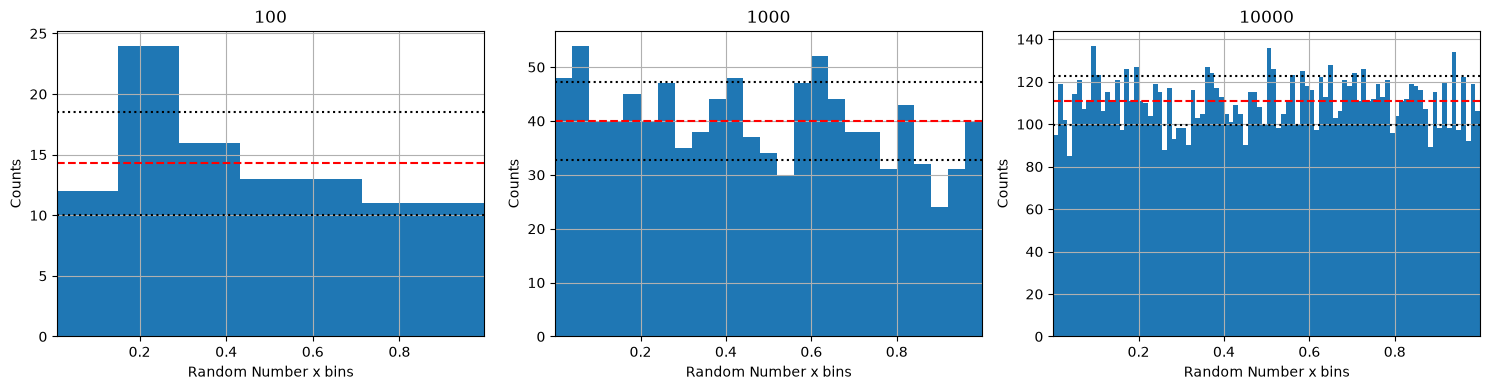

In [1]:
import numpy as np
import matplotlib.pyplot as plt 

def random_histogram(ax,n_random, n_bins):
    random_data = np.random.uniform(0,1,n_random)
    
    counts, bins = np.histogram(random_data, n_bins)
    mean_freq = np.mean(counts)
    std_freq = np.std(counts)
    
    ax.hist(random_data, n_bins)
    ax.axhline(y = mean_freq, color = 'red', linestyle = '--')
    ax.axhline(mean_freq + std_freq, color='k', linestyle=':')
    ax.axhline(mean_freq - std_freq, color='k', linestyle=':')
    
    ax.margins(x=0)
    ax.set_xlabel('Random Number x bins')
    ax.set_ylabel('Counts')
    ax.set_title(n_random)
    ax.grid()

fig, axes = plt.subplots(1,3, figsize=(15,4))

#exploring behaviour with increasing N
random_histogram(axes[0], 100, 7)
random_histogram(axes[1], 1000, 25)
random_histogram(axes[2], 10000, 90)

plt.tight_layout()
plt.show()

***Results*** 
The histograms plotted above test the uniformity of the random number generator. This has a uniform distribution as each bin has an approximately equal number of counts. 

The histograms are plotted with increasing N (numbers generated).  From left to right, N increases from 100 to 1000 to 10000. 

Relative fluctuations decrease as N increases. This is due to the relationship of 

$$
1 / \sqrt(N)
$$

This relationship is consistent with Poisson. This demonstrates the convergence property Monte-Carlo holds.

---

**Task 2** of this project generatese arrays of randomly distributed point in cartesian coordinates (x, y, z) and this data is plotted to confirm its random characteristic.

This is compared with another file - prewritten with spectral issues. Each figure is set to elevation equal to 3, and the azimuthal angle set to -124 for optimal view of spectral issues/randomness.

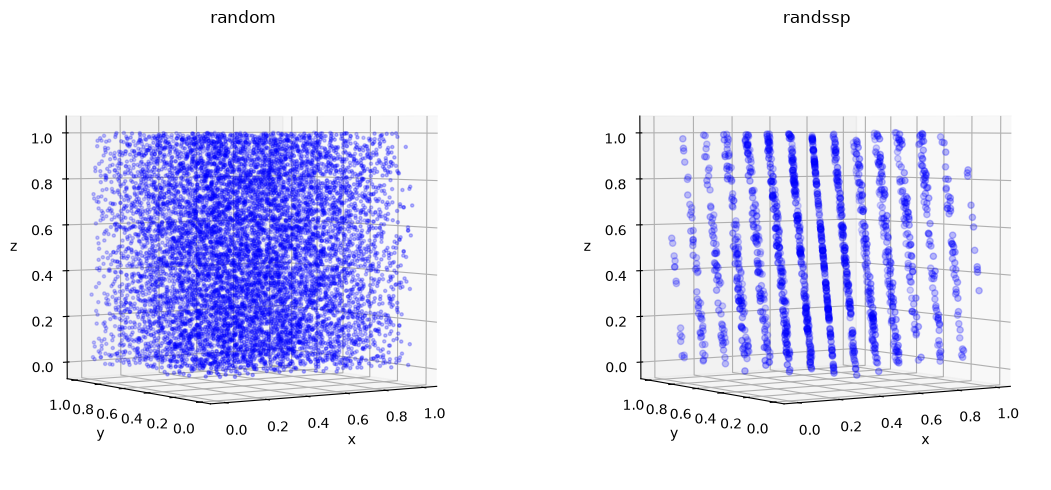

In [2]:
def generate_3d_points(N, lower_bound=0, upper_bound=1):
    return np.random.uniform(lower_bound, upper_bound, (N, 3))

#pre-existing code with spectral issues
def randssp(p,q):
    try: x
    except NameError:
        m = pow(2, 31)
        a = pow(2, 16) + 3
        c = 0
        x = 123456789
    try: p
    except NameError:
        p = 1
    try: q
    except NameError:
        q = p
    
    r = np.zeros([p,q])

    for l in range (0, q):
        for k in range (0, p):
            x = np.mod(a*x + c, m)
            r[k, l] = x/m
    return r

points = generate_3d_points(10000)
x, y, z = points[:,0], points[:,1], points[:,2]
spectra = randssp(3, 1500)

#Plot set-up for two distributions
def setup_sphere(ax, title):
    ax.view_init(3, -124)
    ax.set_box_aspect((1, 1, 1))
    ax.set_title(title)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')

fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.scatter(x, y, z, s=5, alpha=0.6, color ='blue')
setup_sphere(ax1, 'random')

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.scatter(spectra[0], spectra[1], spectra[2], alpha = 0.6, color='blue')
setup_sphere(ax2, 'randssp')

plt.tight_layout()
plt.show()

Figure on the left shows a uniform distribution with no visible structure or clustering bias. This is not the same conclusion for the figure on the right. It can be seen that random points are generated but in planar structures - contradicting true randomness. 

The points appear randomly distributed at first, but the planar bias reveals the points are not isotropic.

This tests the random number generator procedure, highlighting the importance of high quality uniform randomness to produce an accurate Monte-Carlo system.

---

**Task 3** of this project involves constructing a random number generator that produces samples according to the function,

$$
\exp(-x/\lambda)
$$

where lambda is the mean free path. 
In the absence of scattering, the characteristic attenuation length of water follows an exponential decay law and can be determined. This is using the relationship below:

$$
\text{gradient} = -\frac{1}{\lambda}.
$$

By taking the negative reciprocal of the fitted gradient the characteristic attenuation length of water is determined. Using the information below in **Table 1**.


$$
\begin{array}{l c}
\hline
\textbf{Properties of Water} & \textbf{Values} \\
\hline
\text{Absorption cross-section } \sigma_a \, (\text{barns}) & 0.6652 \\
\text{Scattering cross-section } \sigma_s \, (\text{barns}) & 103.0 \\
\text{Density } \rho \, (\text{g/cm}^3) & 1.00 \\
\text{Molar mass } M \, (\text{g/mol}) & 18.0153 \\
\hline
\end{array}
$$

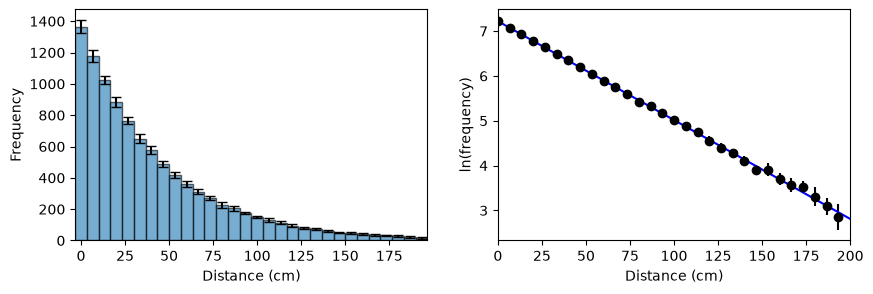

In [3]:
r_limit = 200 #limits at 200cm

def exp_random_generator(n_iterations, n_particles, n_bins, lambda_n, r_max):
    data = np.zeros((n_iterations, n_bins))
    mean_data = np.zeros((n_bins))
    std_data = np.zeros((n_bins))

    for i in range(n_iterations):
        U = np.random.uniform(size = n_particles)
        values = -lambda_n * np.log(U)
        data[i, :], r = np.histogram(values, bins=n_bins, range = (0, r_max))
    r = r[:-1]

    for i in range(n_bins):
        mean_data[i] = np.mean(data[:,i])
        std_data[i] = np.std(data[:,i])
        
    r = np.delete(r, np.argwhere(mean_data==0))
    std_data = np.delete(std_data, np.argwhere(mean_data ==0))
    mean_data = np.delete(mean_data, np.argwhere(mean_data ==0))

    return mean_data, r, r_max/n_bins, std_data
    
#call function
mean_values, r, bin_wid, stand_dev = exp_random_generator(10, 10000, 30, 45, r_limit)

#log graph to determine attenuation length
y = np.log(mean_values)
sigma_y = stand_dev / mean_values
coefficient, cov = np.polyfit(r, y, 1, w=1/sigma_y, cov=True)
m = coefficient[0]
c = coefficient[1]

x_fit = np.linspace(0, r_limit, 200)
y_fit = m * x_fit + c
attenuation_length = -1 / m
attenuation_err = np.sqrt(cov[0,0]) / (m**2)

def plot_histogram_mean(ax, r, mean_data, bin_width, std_data):
    ax.bar(r, mean_data, width=bin_width, edgecolor='k', alpha=0.6)
    ax.errorbar(r, mean_data, yerr=std_data, color='k', fmt='none', capsize=bin_width / 2)
    ax.set_xlabel("Distance (cm)")
    ax.set_ylabel("Frequency")
    ax.margins(x=0)

figure, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3), dpi=100)

plot_histogram_mean(ax1, r, mean_values, bin_wid, stand_dev)

ax2.margins(x=0)
ax2.errorbar(r, y, yerr=sigma_y, fmt='o', color='k')
ax2.plot(x_fit, y_fit, 'b-')
ax2.set_xlabel("Distance (cm)")
ax2.set_ylabel("ln(frequency)")

plt.show()

In [4]:
print("The calculated",f"attenuation length = {attenuation_length:.2f}  ± {attenuation_err:.2f} m", "is within one standard deviation of the expected theoretical value, 45cm.")

The calculated attenuation length = 45.34  ± 0.16 m is within one standard deviation of the expected theoretical value, 45cm.


By completing 10 Monte Carlo iterations, bins counts were averaged to produce a mean histogram with uncertainties estimated from the standard deviation across iterations. A clear exponential decay is observed in attenuation length and confirms the relationship between x, y and the characteristic attenuation length. This is followed by a logarithmic graph to produce a linear relationship and extract the gradient using the relationship:

$$
\text{gradient} = -\frac{1}{\lambda}.
$$

The gradient is the negative reciprocal of the attenuation length as outlined above. The final value is within one standard deviation of 45cm which is expected and consistent with the exponential decay law.

---
For **task 4** of the report, we will explore iostropic unit vectors to model the random motion of neutrons in 3 dimensions.  Each vector is defined as:

$$
\mathbf{r} = x\hat{i} + y\hat{j} + z\hat{k}
$$

$$
|\mathbf{r}| = 1
$$

This will be visually confirmed and plotted as a sphere to check randomness. This is calculated in spherical polar coordinates as seen below:

$$
x = \sin\theta \cos\phi
$$

$$
y = \sin\theta \sin\phi
$$

$$
z = \cos\theta
$$

In [5]:
#uniform distribution
def isotropic_vectors(vector_n):
    u = np.random.uniform(-1, 1, vector_n)
    phi = np.random.uniform(0, 2*np.pi, vector_n)

    x = np.sqrt(1 - u**2) * np.cos(phi)
    y = np.sqrt(1 - u**2) * np.sin(phi)
    z = u
    return x, y, z

#clustering function (not taking solid angle into account)
def clustered_vectors(n):
    theta = np.random.uniform(0, np.pi, n)
    phi = np.random.uniform(0, 2*np.pi, n)

    x = np.sin(theta) * np.cos(phi)
    y = np.sin(theta) * np.sin(phi)
    z = np.cos(theta)
    return x, y, z

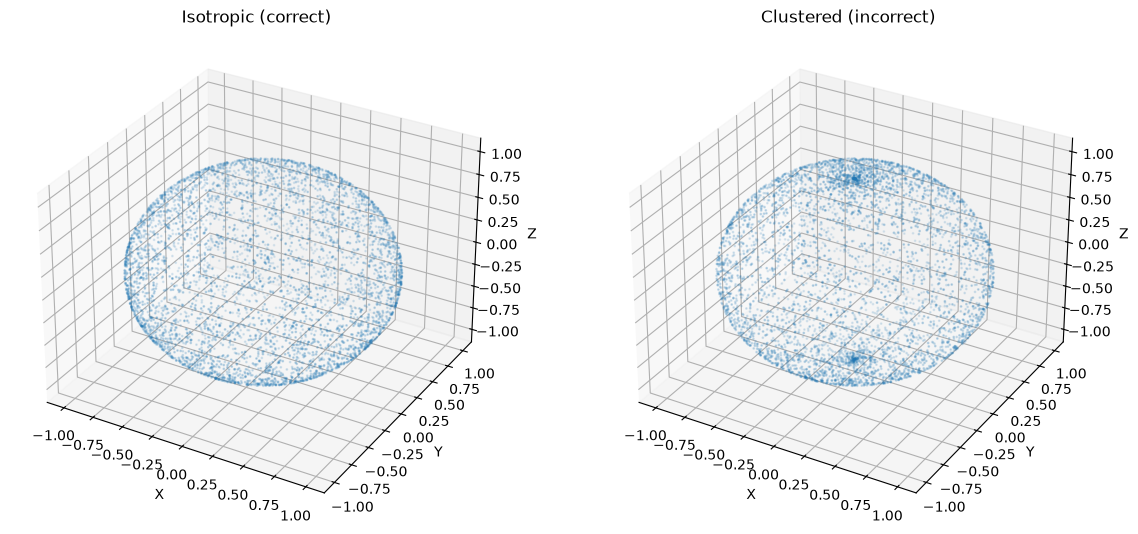

In [6]:
n = 5000

x1, y1, z1 = isotropic_vectors(n)
x2, y2, z2 = clustered_vectors(n)

fig = plt.figure(figsize=(14, 14))

ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(x1, y1, z1, s=1, alpha=0.5)
ax1.set_title("Isotropic (correct)")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")

ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(x2, y2, z2, s=1, alpha=0.5)
ax2.set_title("Clustered (incorrect)")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_zlabel("Z")

plt.show()

Two figures are shown above. The left figure has a uniform distribution, a truly random and isotropic sampling with no pattern or directional bias. The figure on the right is not isotropic, it shows clustering in the poles. 

This is due to data in equal intervals of $\theta$, cause clustering near $\theta$ = 0 or $\pi$.
rather than sampling uniformly in solid angle. In spherical coordinates, equal spacing in $\theta$ does not correspond to equal areas on the unit sphere. As a result, regions near $\theta = 0$ and $\theta = \pi$ (the poles) become over-represented.

This occurs because a small change in $\theta$ near the poles corresponds to a much smaller surface area element compared to regions near the equator. Consequently, points become artificially concentrated at the north and south poles, while the equatorial region is under-sampled.

This demonstrates that uniform sampling in coordinate space does not guarantee uniform sampling in physical space.

---
Similarly, **task 5** extends the isotropic approach with uniformly distributed scattering directions with exponentially distributed step lengths, modelling the stochastic motion of neutrons in a scattering medium.

The resulting trajectories exhibit characteristic random walk behaviour, where particles undergo a sequence of straight-line steps with randomly oriented directions and step lengths sampled from

$$
P(x) = \exp(-x/\lambda)
$$.

In [7]:
def isotropic_walk(n_steps, mean_free_path):
    
    ux, uy, uz = isotropic_vectors(n_steps)

    step_lengths = -mean_free_path * np.log(np.random.uniform(size=n_steps))

    dx = step_lengths * ux
    dy = step_lengths * uy
    dz = step_lengths * uz

    x = np.zeros(n_steps)
    y = np.zeros(n_steps)
    z = np.zeros(n_steps)
    
    #next step
    for i in range(1, n_steps):
        x[i] = x[i-1] + dx[i]
        y[i] = y[i-1] + dy[i]
        z[i] = z[i-1] + dz[i]

    return x, y, z, step_lengths

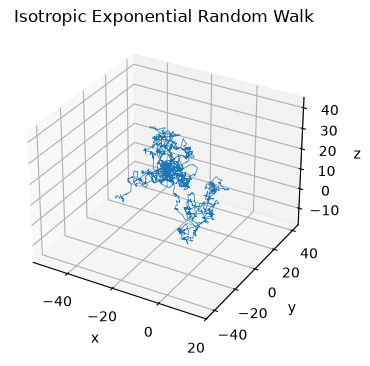

In [8]:
#plotting random neutron walk
x, y, z, steps = isotropic_walk(2000, 1.0)

fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot(111, projection='3d')

ax.plot(x, y, z, linewidth=0.5)

ax.set_title("Isotropic Exponential Random Walk")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

plt.show()

The data below is used to calculate the macroscopic absorption and scattering cross-sections. This is used to determine the probability of absorption and the mean free path of water, lead and graphite.

In [9]:
# Water
avogadro = 6.022e23 #per mole
absorption_w = 0.6652e-24
scattering_w = 103e-24
density_w = 1.00 #g/cm^3
molar_mass_w = 18.0153 #g/mol

# Lead
absorption_l = 0.158e-24
scattering_l = 11.221e-24
density_l = 11.35
molar_mass_l = 207.2

#Graphite
absorption_g = 0.0045e-24
scattering_g = 4.74e-24
density_g = 1.67
molar_mass_g = 12.011

In [10]:
def material_properties(absorption, scattering, density, molar_mass):

    number_dens = (density * avogadro) / molar_mass

    macro_abs = number_dens * absorption
    macro_scat = number_dens * scattering

    total = macro_abs + macro_scat
    mfp = 1 / total

    return macro_abs, macro_scat, mfp

w_macs, w_scs, w_mfp = material_properties(absorption_w, scattering_w, density_w, molar_mass_w)
Pb_macs, Pb_scs, Pb_mfp = material_properties(absorption_l, scattering_l, density_l, molar_mass_l)
g_macs, g_scs, g_mfp = material_properties(absorption_g, scattering_g, density_g, molar_mass_g)

---

**Task 6** aims to visualise the random neutron paths in 10cm of water, graphite or lead. The path across the y-z plane is plotted below.

In [11]:
def isotropic_vector():
    u = np.random.uniform(-1, 1)
    phi = np.random.uniform(0, 2*np.pi)

    x = np.sqrt(1 - u**2) * np.cos(phi)
    y = np.sqrt(1 - u**2) * np.sin(phi)
    z = u

    return x, y, z

In [12]:
def neutron_walk(L, mfp, sigma_a, sigma_s, isotropic_vector):

    p_absorb = sigma_a / (sigma_a + sigma_s)

    x, y, z = [0], [0], [0]
    dir_x, dir_y, dir_z = isotropic_vector()

    while True:

        step = -mfp * np.log(np.random.uniform())

        x_new = x[-1] + step * dir_x
        y_new = y[-1] + step * dir_y
        z_new = z[-1] + step * dir_z

        x.append(x_new)
        y.append(y_new)
        z.append(z_new)

        if x_new < 0:
            return np.array(x), np.array(y), np.array(z), "reflected"

        if x_new > L:
            return np.array(x), np.array(y), np.array(z), "transmitted"

        if np.random.uniform() < p_absorb:
            return np.array(x), np.array(y), np.array(z), "absorbed"

        dir_x, dir_y, dir_z = isotropic_vector()
    
def N_outcomes(mfp, sigma_a, sigma_s, isotropic_vector, N, L):

    outcomes = {"reflected": 0, "transmitted": 0, "absorbed": 0}
    trajectories = []

    for _ in range(N):

        x, y, z, outcome = neutron_walk(L, mfp, sigma_a, sigma_s, isotropic_vector)

        outcomes[outcome] += 1
        trajectories.append((x, y, z))

    return outcomes, trajectories

w_L = 10   #cm
pb_L = 10
g_L = 10

w_outcomes, w_trajectories = N_outcomes(w_mfp, w_macs, w_scs, isotropic_vector, 10, L=w_L)

pb_outcomes, pb_trajectories = N_outcomes(Pb_mfp, Pb_macs, Pb_scs, isotropic_vector, 10, L=pb_L)

g_outcomes, g_trajectories = N_outcomes(g_mfp, g_macs, g_scs, isotropic_vector, 10, L=g_L)

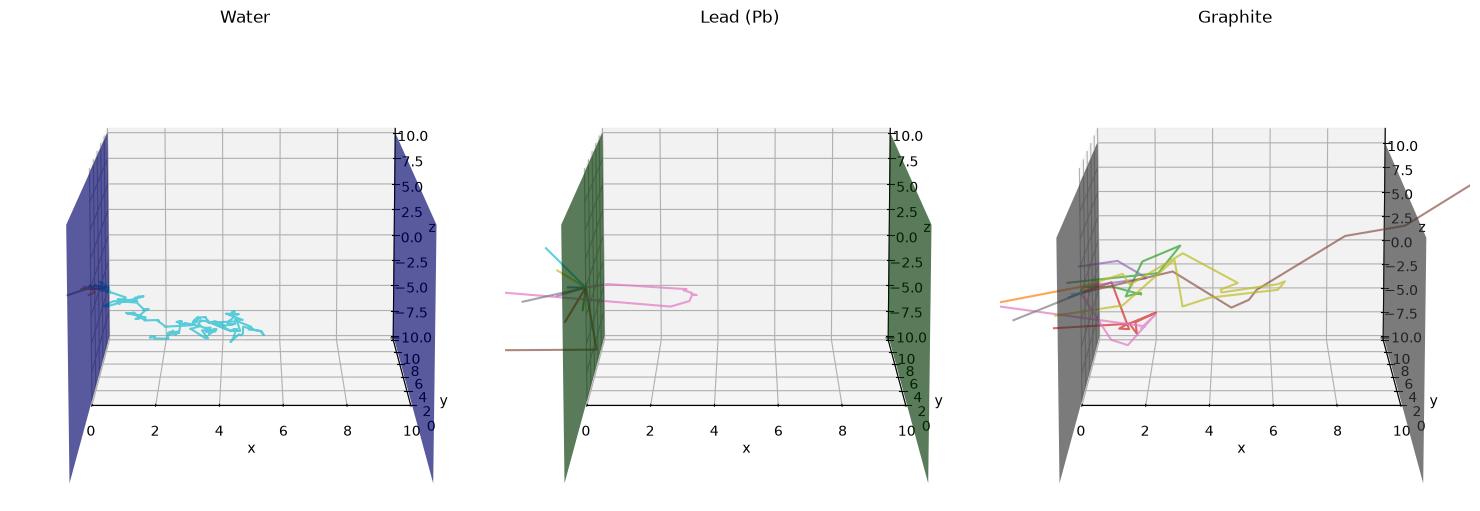

In [13]:
fig = plt.figure(figsize=(15,5))

ax1 = fig.add_subplot(131, projection='3d')
ax2 = fig.add_subplot(132, projection='3d')
ax3 = fig.add_subplot(133, projection='3d')

y = np.linspace(-10, 10, 2)
z = np.linspace(-10, 10, 2)
Y, Z = np.meshgrid(y, z)

#visualising start and end of material
def slab(ax, L, color):

    X0 = np.zeros_like(Y)
    X1 = np.full_like(Y, L)

    ax.plot_surface(X0, Y, Z, color=color, alpha=0.65, linewidth=0)
    ax.plot_surface(X1, Y, Z, color=color, alpha=0.65, linewidth=0)

for x, y, z in w_trajectories:
    ax1.plot(x, y, z, alpha=0.7)

slab(ax1, w_L, "blue")
ax1.set_title("Water")

for x, y, z in pb_trajectories:
    ax2.plot(x, y, z, alpha=0.7)

slab(ax2, pb_L, "green")
ax2.set_title("Lead (Pb)")

for x, y, z in g_trajectories:
    ax3.plot(x, y, z, alpha=0.7)

slab(ax3, g_L, "grey")
ax3.set_title("Graphite")

#plotting
for ax, L in zip([ax1, ax2, ax3], [w_L, pb_L, g_L]):
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")

    ax.set_xlim(0, L)
    ax.set_ylim(0,L)
    ax.view_init(elev=10, azim=-90)
    ax.margins(x=0)

plt.tight_layout()
plt.show()

Each figure above is modelled as a 10cm slab of their respective material. This is shown by two slabs of colour to indicate the start and end of the material. The differences in neutron behaviour are due to the variations in absorption and scattering cross-sections.

Water has a high reflection probability with almost all particles reflected. This is also due to the small sample of neutrons used. Water has a high proportion of hydrogen with leads to dominating scattering effects. This is explored further below by simulating a larger number of neutrons.

Lead is observed to reflect less neutrons than water, allowing some to be absorbed and a few to be transmitted. Transmission is noticeably greater than water due to a reduced scattering cross-section.

Graphite is observed to have the greatest transmission rates and very few neutrons are absorbed. This a key property in its function as a moderator, preventing neutron losses.

Overall, we can conclude the material properties are the main variables in how neutrons interact with the slabs, independent of slab thickness.

**Quantifying Scattering Processes**: 

Setting L = 0, **task 7** of the report will repeat the last exercise to determine absorption, reflection and transmission rates. This is by counting the number of neutrons absorbed, reflected and transmitted to calculate ratios:
$$
R = \frac{N_R}{N}, \quad T = \frac{N_T}{N}, \quad A = \frac{N_A}{N}
$$
and fixing the number of neutrons at a higher value (N=10000) to reduce relative fluctuations. 

This section will also calculate the associated uncertainties for these rates via binomial statistics given by:
$$
\sigma_p = \sqrt{\frac{p(1-p)}{N}}
$$

Binomial distribution is used here becuase each neutron in my simulation is undergoing a random process with only a few possible outcomes of fixed probability. Each event is modelled by Bernoulli and a large number of Bernoulli events can be modelled by the Binomial distribution. This is constrained by assuming neutrons are independent and there is no time dependence on material properties.

In [14]:
def simulate_material(lam, macro_abs, macro_scat, L=10, N_particles=10000, N_runs=10):
    
    Pabs = macro_abs / (macro_abs + macro_scat) #probability of absorption
    num_ref = np.zeros(N_runs)
    num_transmission = np.zeros(N_runs)
    num_absorption = np.zeros(N_runs)

    for run in range(N_runs):

        x = -lam * np.log(np.random.uniform(size=N_particles))

        while len(x) > 0:

            u = np.random.uniform(size=len(x))
            #setting boundaries to classify interaction
            ref_mask = (x < 0)
            trans_mask = (x > L)
            in_slab = (x > 0) & (x < L)
            abs_mask = in_slab & (u < Pabs)

            num_ref[run] += np.count_nonzero(ref_mask)
            num_transmission[run] += np.count_nonzero(trans_mask)
            num_absorption[run] += np.count_nonzero(abs_mask)
            
            #removing counted neutrons
            survive = ~(ref_mask | trans_mask | abs_mask)
            x = x[survive]

            mu = np.random.uniform(-1, 1, size=len(x))
            r = -lam * np.log(np.random.uniform(size=len(x)))
            x += r * mu

    mean_ref_rate = np.mean(num_ref / N_particles)
    mean_trans_rate = np.mean(num_transmission / N_particles)
    mean_absorb_rate = np.mean(num_absorption / N_particles)
    
    #binomial errors
    err_ref = np.sqrt(mean_ref_rate * (1 - mean_ref_rate) / (N_particles))
    err_trans = np.sqrt(mean_trans_rate * (1 - mean_trans_rate) / (N_particles))
    err_abs = np.sqrt(mean_absorb_rate * (1 - mean_absorb_rate) / (N_particles))

    return (mean_ref_rate, err_ref,mean_trans_rate, err_trans,mean_absorb_rate, err_abs)

w = simulate_material(w_mfp, w_macs, w_scs)
Pb = simulate_material(Pb_mfp, Pb_macs, Pb_scs)
g = simulate_material(g_mfp, g_macs, g_scs)

for name, res in [("Water", w), ("Lead", Pb), ("Graphite", g)]:
    R, dR, T, dT, A, dA = res
    print(name)
    print(f"Reflection = {R:.4f} ± {dR:.4f}, Transmission = {T:.4f} ± {dT:.4f}, Absorption = {A:.4f} ± {dA:.4f}\n")

Water
Reflection = 0.7958 ± 0.0040, Transmission = 0.0037 ± 0.0006, Absorption = 0.2005 ± 0.0040

Lead
Reflection = 0.6174 ± 0.0049, Transmission = 0.2822 ± 0.0045, Absorption = 0.1004 ± 0.0030

Graphite
Reflection = 0.6865 ± 0.0046, Transmission = 0.3058 ± 0.0046, Absorption = 0.0078 ± 0.0009



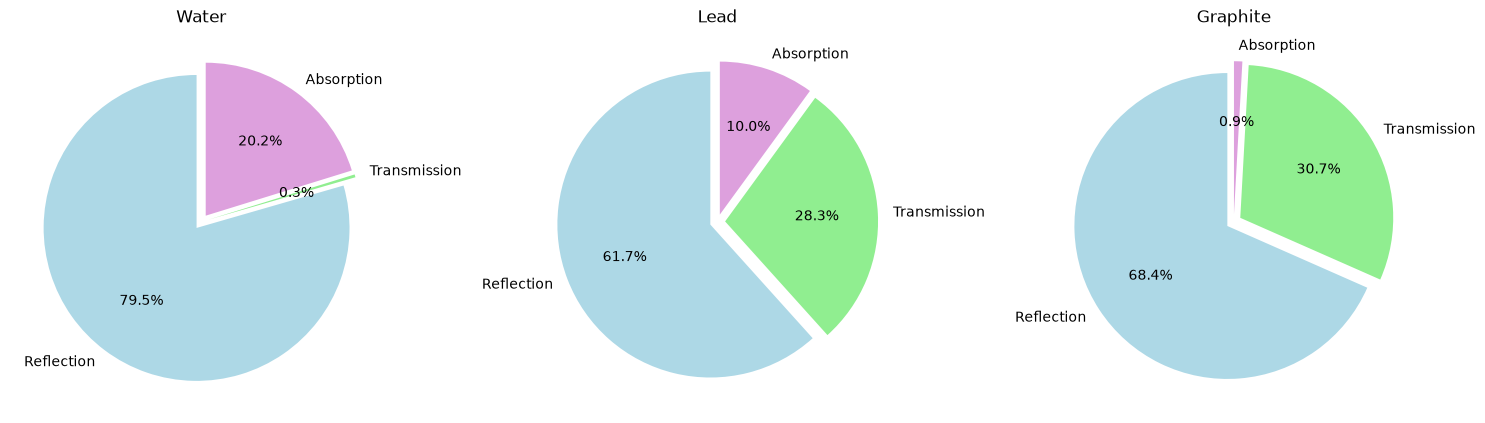

In [15]:
#Pie chart to compare outcome probabilities
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

explode = (0.05, 0.05, 0.05)

data = [("Water", simulate_material(w_mfp, w_macs, w_scs)), ("Lead", simulate_material(Pb_mfp, Pb_macs, Pb_scs)), ("Graphite", simulate_material(g_mfp, g_macs, g_scs))]

for ax, (name, res) in zip(axes, data):

    R, dR, T, dT, A, dA = res
    values = [R, T, A]
    labels = ["Reflection", "Transmission", "Absorption"]
    ax.pie(values,labels=labels,autopct="%.1f%%",
        colors=["lightblue", "lightgreen", "plum"], explode=explode, startangle=90)
    ax.set_title(name)

plt.tight_layout()
plt.show()

**Results**

Water has a significantly higher reflection probability than lead and graphite and a much lower transmission probability. This is due to the strong scattering properties arising from the large scattering cross-section of hydrogen. 

Lead is a dense material but the neutron interaction is less dominated by scattering motion. It has a moderate reflection probability compared to water and a higher transmission value.

Graphite has the highest transmission probability and lowest absorption probability. This is consistent with its small macroscopic absorption cross-section. Neutrons are able to travel further through graphite than lead or water.

---

**Task 8** investigates the relationship between interaction probabilities and thickness of material. The range of thickness ranges from 1 to 25cm. The expected behaviour is modelled by the Beer-Lambert Law which predicts and exponential attenuation of transmitted neutrons.

$$
T(L) = T_0  \exp\left(-\frac{L}{\lambda}\right)
$$

In [16]:
def thickness_dependence(lam, macro_abs, macro_scat, N_particles=10000, N_runs=10):
    #setting range of thickness
    L_values = np.linspace(1, 25, 20)

    A = np.zeros(len(L_values))
    R = np.zeros(len(L_values))
    T = np.zeros(len(L_values))

    A_err = np.zeros(len(L_values))
    R_err = np.zeros(len(L_values))
    T_err = np.zeros(len(L_values))

    for i, L in enumerate(L_values):

        A_runs = np.zeros(N_runs)
        R_runs = np.zeros(N_runs)
        T_runs = np.zeros(N_runs)

        for run in range(N_runs):

            R_run, _, T_run, _, A_run, _ = simulate_material(lam, macro_abs, macro_scat, L, N_particles, 1)

            R_runs[run] = R_run
            T_runs[run] = T_run
            A_runs[run] = A_run

        A[i] = np.mean(A_runs)
        R[i] = np.mean(R_runs)
        T[i] = np.mean(T_runs)

        A_err[i] = np.sqrt(A[i] * (1 - A[i]) / (N_particles * N_runs))
        R_err[i] = np.sqrt(R[i] * (1 - R[i]) / (N_particles * N_runs))
        T_err[i] = np.sqrt(T[i] * (1 - T[i]) / (N_particles * N_runs))
        
    return L_values, A, R, T, A_err, R_err, T_err

Water: λ = 1.875 ± 0.036 cm
Lead: λ = 9.529 ± 0.261 cm
Graphite: λ = 11.875 ± 0.576 cm


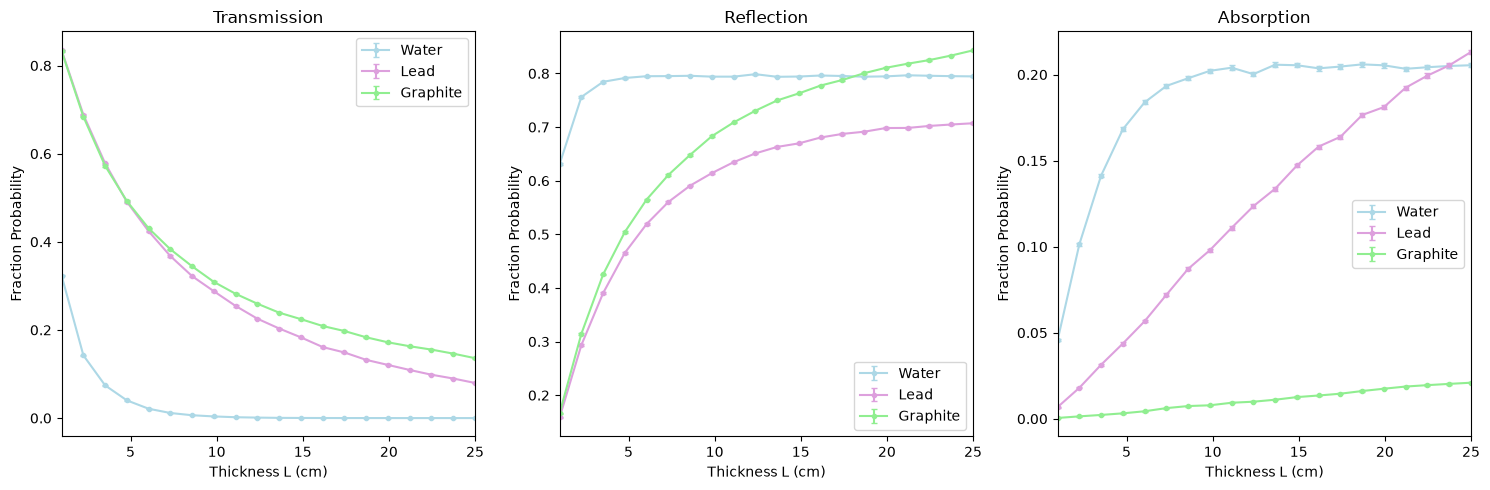

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15,5))

materials = [("Water", w_mfp, w_macs, w_scs, "lightblue"), ("Lead", Pb_mfp, Pb_macs, Pb_scs, "plum"), ("Graphite", g_mfp, g_macs, g_scs, "lightgreen")]

for name, lam, mac_abs, mac_scat, color in materials:

    L_values, A, R, T, A_err, R_err, T_err = thickness_dependence(lam, mac_abs, mac_scat, N_particles=10000, N_runs=10)
    #mask for logarithmic plot
    mask = T > 0

    L_fit = L_values[mask]
    T_fit = T[mask]
    T_err_fit = T_err[mask]

    y = np.log(T_fit)
    sigma_y = T_err_fit / T_fit
    coefficient, cov = np.polyfit(L_fit, y, 1, w=1/sigma_y, cov=True)
    m = coefficient[0]
    lam_att = -1 / m
    lam_err = np.sqrt(cov[0, 0]) / (m**2)

    print(f"{name}: λ = {lam_att:.3f} ± {lam_err:.3f} cm")

    axes[0].errorbar( L_values, T, yerr=T_err, fmt='o-', capsize=2, markersize=3, color=color, label=name)
    axes[1].errorbar(L_values, R, yerr=R_err, fmt='o-', capsize=2, markersize=3,color=color, label=name)
    axes[2].errorbar(L_values, A, yerr=A_err, fmt='o-', capsize=2, markersize=3, color=color, label=name)

axes[0].set_title("Transmission")
axes[1].set_title("Reflection")
axes[2].set_title("Absorption")

for ax in axes:
    ax.set_xlabel("Thickness L (cm)")
    ax.set_ylabel("Fraction Probability")
    ax.legend()
    ax.margins(x=0)

plt.tight_layout()
plt.show()

**Results**

The absorption proabilities increases with thickness. This is due to neutrons taking longer paths and a higher probability of being absorbed.  Absorption dominates over tranmission at large limit L.

The reflection probability increases initially as more neutrons undergo scattering back to the initial boundary. However, this saturates at larger L.

It can be observed there is an exponential decay for transmission probabilities as the slab thickness increases. This is consistent with the Beer-Lambert law and can be used to calculate the attenuation lengths.

$$
\lambda_{\text{water}} \ll \lambda_{\text{lead}} < \lambda_{\text{graphite}}
$$

Water exhibits the shortest attenuation length which leads to low transmission probability.

Lead has a significant larger attenuation length compared to water and graphite has the largest attenuation length so neutrons can travel further before interaction.

---

## Stretch yourself: Woodcock Method

The Woodcock method is used to simulate neutrons paths travelling through slabs of varying material. In this section, we will be focusing on two types with the first always having a higher attenuation length. 

The method defines a maximum macroscopic cross-section of a combination of the two individual cross-sections.

Constraining the first material to have a longer attenuation length ensures the first slab is the only material where fictitious steps are possible. Fictitious collisions mean the particle continues in the same direction without changing state. Real collisions undergo scattering and absorption. 

Its efficiency is dependent on how similar the maximum cross-section matches the individual cross-sections. A large contrast in properties increases the proportion of null-collisions. This experiment explores lead to water, graphite to water and graphite to lead methods.

In [18]:
def woodcock(name, lam1, lam2, Pabs1, Pabs2, L=10, N_particles=10000, N_runs=10):

    num_ref = np.zeros(N_runs)
    num_transmission = np.zeros(N_runs)
    num_absorption = np.zeros(N_runs)

    #defining overall properties
    sig1 = 1 / lam1
    sig2 = 1 / lam2
    sigT = max(sig1, sig2)
    lamT = min(lam1, lam2)

    for run in range(N_runs):

        x = np.zeros(N_particles)
        mu = np.ones(N_particles)

        while len(x) > 0:
            step = -lamT * np.log(np.random.uniform(size=len(x)))
            x_new = x + step * mu
            #defining boundaries
            ref_mask = (x_new < 0)
            trans_mask = (x_new > L)

            num_ref[run] += np.count_nonzero(ref_mask)
            num_transmission[run] += np.count_nonzero(trans_mask)
            #deleting counted particles
            alive = ~(ref_mask | trans_mask)
            x = x_new[alive]
            mu = mu[alive]

            if len(x) == 0:
                break

            in_slab2 = x > L / 2

            sig_local = np.where(in_slab2, sig2, sig1)
            p_real = sig_local / sigT
            # fictitious = no change in direction
            fict = np.random.uniform(size=len(x)) > p_real
            real = ~fict

            pabs = np.where(in_slab2, Pabs2, Pabs1)
            abs_mask = real & (np.random.uniform(size=len(x)) < pabs)
            num_absorption[run] += np.count_nonzero(abs_mask)
            alive = ~abs_mask
            x = x[alive]
            mu = mu[alive]

            if len(x) == 0:
                break

            mu_new = 2 * np.random.uniform(size=len(x)) - 1
            mu = np.where(real[alive], mu_new, mu)

    mean_ref_rate = np.mean(num_ref / N_particles)
    mean_trans_rate = np.mean(num_transmission / N_particles)
    mean_abs_rate = np.mean(num_absorption / N_particles)

    err_ref = np.sqrt(mean_ref_rate * (1 - mean_ref_rate) / (N_particles * N_runs))
    err_trans = np.sqrt(mean_trans_rate * (1 - mean_trans_rate) / (N_particles * N_runs))
    err_abs = np.sqrt(mean_abs_rate * (1 - mean_abs_rate) / (N_particles * N_runs))

    print(f"\n--- {name} ---")
    print(f"Reflection rate   : {mean_ref_rate:.5f} ± {err_ref:.5f}")
    print(f"Transmission rate : {mean_trans_rate:.5f} ± {err_trans:.5f}")
    print(f"Absorption rate   : {mean_abs_rate:.5f} ± {err_abs:.5f}")
    
    return (mean_ref_rate, err_ref,
        mean_trans_rate, err_trans,
        mean_abs_rate, err_abs)
#Probabilities of Absorption
Pabs_lead = Pb_macs / (Pb_macs + Pb_scs)
Pabs_water = w_macs / (w_macs + w_scs)
Pabs_graphite = g_macs / (g_macs + g_scs)

results = {}
results["Pb-Water"] = woodcock("Lead to Water", Pb_mfp, w_mfp, Pabs_lead, Pabs_water)
results["Graphite-Water"] = woodcock("Graphite to Water", g_mfp, w_mfp, Pabs_graphite, Pabs_water)
results["Graphite-Pb"] = woodcock("Graphite to Lead", g_mfp, Pb_mfp, Pabs_graphite, Pabs_lead)


--- Lead to Water ---
Reflection rate   : 0.75848 ± 0.00135
Transmission rate : 0.02596 ± 0.00050
Absorption rate   : 0.21556 ± 0.00130

--- Graphite to Water ---
Reflection rate   : 0.82440 ± 0.00120
Transmission rate : 0.02789 ± 0.00052
Absorption rate   : 0.14771 ± 0.00112

--- Graphite to Lead ---
Reflection rate   : 0.66770 ± 0.00149
Transmission rate : 0.29102 ± 0.00144
Absorption rate   : 0.04128 ± 0.00063


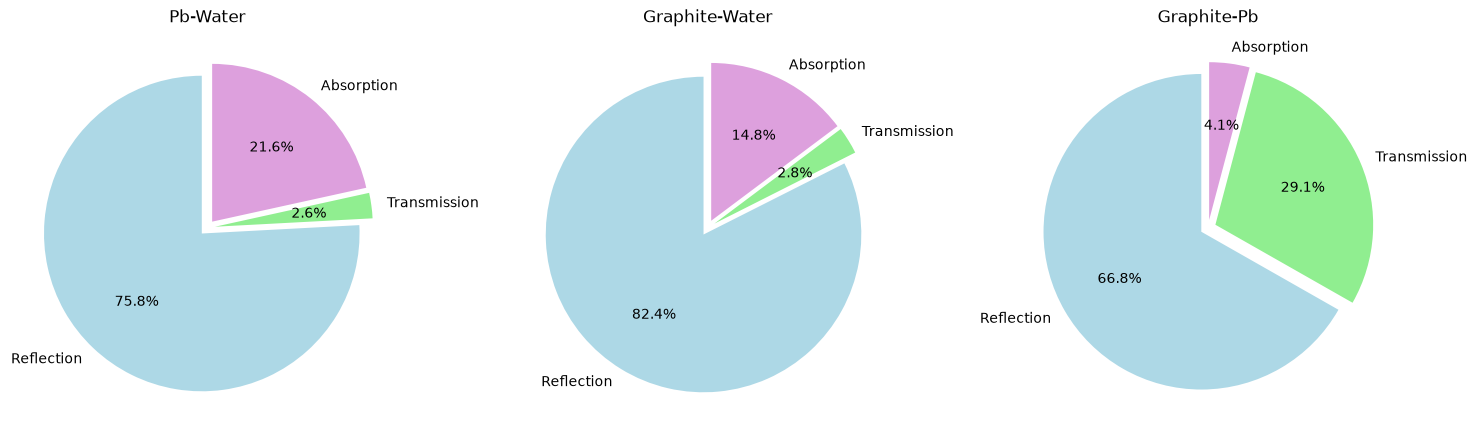

In [19]:
#Pie charts for Woodcock to compare with pure material slabs.
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

explode = (0.05, 0.05, 0.05)

for ax, (name, res) in zip(axes, results.items()):

    R, _, T, _, A, _ = res

    ax.pie([R, T, A],labels=["Reflection", "Transmission", "Absorption"], autopct="%.1f%%",
        colors=["lightblue", "lightgreen", "plum"], explode=explode, startangle=90)
    ax.set_title(name)

plt.tight_layout()
plt.show()

**Results of the Woodcock Method**

Compared to pure water, the lead-water system has a significantly higher transmission probability and reduced absorption probability. The lead layer reduces neutron energy loss through scattering allowing more neutrons to exit the water layer. Reflection still remains high due to dominating scattering properties of water.

The graphite-water simulation has slightly higher reflection and transmission probabilities than pure water. The increase in transmission is due to the graphite's low absorption cross-section.

The graphite-lead simulation, shows the highest transmission rates out of all 6 simulations ran in this project. This is consistent with the weak attenuation of graphite and moderate scattering rates in lead. The low absorption probability suggest neutron loss is mostly due to scattering.

## Conclusion

The Monte Carlo simulation run shows the dependence of interaction probabilites on material properties. Water is the most effective moderator due to its high scattering cross-section and short attenuation length. It is used in nuclear reactors to control neutron numbers. Similarly, graphite is also a useful moderator, but it exhibits the highest transmission out of the three materials.

Lead is a intermediate balance between these two materials and is primarily applied in radiation shielding, for example, as protective gear during medical diagnosis/treatments.

The Woodcock method shows that neutron interactions are not defined by combining individual properties. The interfaces and order of materials cause significant effects on the neutron paths.

Overall this project has shown the importance of uniform and truly random numbers in Monte Carlo. The application of this in producing isotropic unit vectors in 3 dimensions and exponential steps to simulate neutrons. This was applied to pure material slabs of 10cm (graphite, water and lead). Finishing with the woodcock method, exploring heterogeneous slab behaviours and its comparison with pure slabs.